# Postprocessing

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os
import myfunctions
import h5py
import TM26_unet as unet


GPU = True
MULTIGPU = True

DELETE_OLD_FILES = False
DELETE_OLD_FILES = False

SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True

diffLimDir = "dataInputs/"
testDataDir = "output_prep/"
outputDir = "output_post/"
inputDir = "output_infer/"

Exposures = [10, 100, 1000, 5000]

# datasets_name = ["lightfield", "WFSxy", "WFSxy_DM", "WFSxy_DM_intensity", "WFSxy_intensity"]
datasets_name = ["WFSxy_DM"]
dataset_name_readable = [f"WFSxy and DM commands: {Exposures}it", f"WFSxy, SHWFS intensity map and DM commands: {Exposures}it"]


D = 17.5e-3  # [m]
wl = 632.8e-9  # [m]
pad = 2
dx = 3.928571e-06

SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True

for i in range(len(datasets_name)):
    os.makedirs(outputDir + datasets_name[i], exist_ok=True)

dataset_numbers = len(datasets_name)

### Inference data

In [2]:
for dataset_number in range(dataset_numbers):
    if datasets_name[dataset_number] == "lightfield":
        
        with h5py.File(inputDir+datasets_name[dataset_number]+"/predictions.h5", 'r') as temp:
            inferences = temp[list(temp.keys())[0]][()]
        with h5py.File("dataInputs/ipsf_difflim.h5", 'r') as temp:
            dx_scaling = temp[list(temp.keys())[0]][()].shape[1]/inferences.shape[1]
            ipsf_difflim = myfunctions.pixel_adder(temp[list(temp.keys())[0]][()],final_shape=[inferences.shape[1], inferences.shape[2]])   
            
        truths = np.zeros_like(inferences)
        with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
            key = list(temp.keys())
            tempdata = temp[key[0]][()][:]
            for i in range(tempdata.shape[0]):
                truths[i,:,:] = myfunctions.pixel_adder(tempdata[i],final_shape=[inferences.shape[1], inferences.shape[2]])
        
    else:
        with h5py.File(inputDir+datasets_name[dataset_number]+"/predictions.h5", 'r') as temp:
            inferences = temp[list(temp.keys())[0]][()]
        with h5py.File("dataInputs/ipsf_difflim.h5", 'r') as temp:
            ipsf_difflim = temp[list(temp.keys())[0]][()]
            dx_scaling = temp[list(temp.keys())[0]][()].shape[1]/inferences.shape[1]
        with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
            key = list(temp.keys())
            truths = temp[key[0]][()][:]

    x_max = np.genfromtxt("output_ML/"+datasets_name[dataset_number]+"/max_val.txt", delimiter=',', dtype=None, encoding='utf-8')[0][1]
    y_max = np.genfromtxt("output_ML/"+datasets_name[dataset_number]+"/max_val.txt", delimiter=',', dtype=None, encoding='utf-8')[1][1]
    dx_scaled = dx*dx_scaling

    

In [3]:
    padded_ipsf_difflim = myfunctions.pad_center(ipsf_difflim, pad)        
    padded_truth = myfunctions.pad_center(truths/y_max, pad)
    padded_inferences = myfunctions.pad_center(inferences,pad)

    N = ipsf_difflim.shape[1]*pad
    fc = D / wl
    freq = np.fft.fftshift(np.fft.fftfreq(N, d=dx_scaled))
    freq_n = np.abs(freq) / fc
    NU_X, NU_Y = np.meshgrid(freq_n, freq_n)
    nu_n_grid = np.sqrt(NU_X**2 + NU_Y**2)
    # FREQ_MASK = np.abs(freq) < fc
    FREQ_MASK = nu_n_grid < 1

    OTF_ipsf_difflim = np.abs(myfunctions.otf_from_psf(padded_ipsf_difflim))
    OTF_tel = myfunctions.telescope_otf(nu_n_grid)
    OTF_aliasing = OTF_ipsf_difflim - OTF_tel
    OTF_truths = (np.abs(myfunctions.otf_from_psf(padded_truth))[...,:,:] - OTF_aliasing)*FREQ_MASK
    OTF_inferences = (np.abs(myfunctions.otf_from_psf(padded_inferences))[...,:,:] - OTF_aliasing)*FREQ_MASK

    inference_Strehls = np.sum(OTF_inferences, axis=(-2, -1)) / np.sum(OTF_tel*FREQ_MASK)
    truths_Strehls = np.sum(OTF_truths, axis=(-2, -1)) / np.sum(OTF_tel*FREQ_MASK)
    Strehls_difference = truths_Strehls - inference_Strehls
    Strehls_rel_diff = Strehls_difference/truths_Strehls

2654


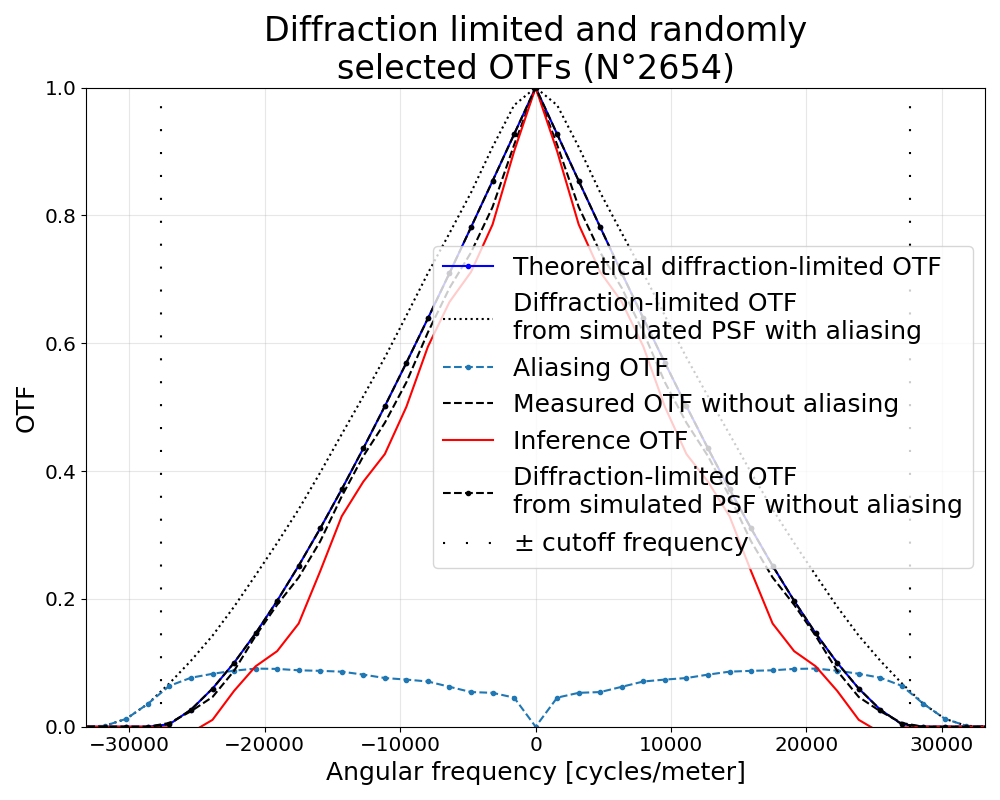

In [9]:
therandom = np.random.randint(0, inferences.shape[0])
print(therandom)
plt.figure(figsize=(10, 8))
plt.plot(freq, OTF_tel[N//2, :], ".-b", label="Theoretical diffraction-limited OTF")
plt.plot(freq, OTF_ipsf_difflim[N//2, :], "k", linestyle="dotted", label="Diffraction-limited OTF\nfrom simulated PSF with aliasing")
plt.plot(freq, OTF_aliasing[N//2, :],"--.",label = "Aliasing OTF")
plt.plot(freq, OTF_truths[therandom,N//2, :],"--k", label="Measured OTF without aliasing")
plt.plot(freq, OTF_inferences[therandom,N//2, :]*FREQ_MASK[N//2,:],'r', label="Inference OTF")
plt.plot(freq, OTF_ipsf_difflim[N//2, :]-OTF_aliasing[N//2, :], "--.k", label="Diffraction-limited OTF\nfrom simulated PSF without aliasing")
plt.vlines([-fc, fc], 0, 1, "k", linestyles=[(0, (1, 10))], label = r"$\pm$ cutoff frequency")
plt.title(f"Diffraction limited and randomly\nselected OTFs (N°{therandom})", fontsize = BIGGER_SIZE)
plt.xlabel("Angular frequency [cycles/meter]", fontsize=SMALL_SIZE)
plt.ylabel("OTF", fontsize=SMALL_SIZE)
plt.xlim([-fc * 1.2, fc * 1.2])
plt.ylim([0, 1])
plt.xticks(fontsize=SMALL_SIZE*.8)
plt.yticks(fontsize=SMALL_SIZE*.8)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=SMALL_SIZE)
plt.tight_layout()

plt.savefig(outputDir + datasets_name[dataset_number]+ f"/{datasets_name[dataset_number]}_iOTF.png")

In [ ]:
plt.figure()
plt.imshow(inferences[therandom])

## Strehl



In [ ]:
lower_bounds = truths_Strehls * 0.9  # -10%
upper_bounds = truths_Strehls * 1.1  # +10%

plt.close('all')
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

# Top plot: Strehl ratios
ax.plot(truths_Strehls, '.k', label=r'$S_{ref}$', markersize=1)
ax.plot(inference_Strehls, '.r', label=r'$S_{R}$', markersize=1)
ax.set_ylim([0, 1])
ax.fill_between(range(len(truths_Strehls)), lower_bounds, upper_bounds, 
                color='gray', alpha=0.3, edgecolor='none', label='±10% of expected Strehl ratio')
ax.set_ylabel('Strehl ratio [-]', fontsize=MEDIUM_SIZE)
ax.tick_params(axis='y', labelsize=SMALL_SIZE)
ax.legend(fontsize=SMALL_SIZE)
ax.set_title("Comparison of Strehl ratios for instantaneous PSFs", fontsize=BIGGER_SIZE)
ax.set_xlim([0, inference_Strehls.shape[0]])
ax.grid()

# Bottom plot: Relative distance (ax2 is now a separate subplot below)
ax2.plot(Strehls_rel_diff * 100, '-k', label=r"$\frac{S_{R}-S_{ref}}{S_{ref}}$",markersize=3)
ax2.set_ylabel('Relative distance [%]', fontsize=MEDIUM_SIZE, color='k')
ax2.tick_params(axis='y', labelsize=SMALL_SIZE, colors='k')
symetric_lim = max(abs(np.min(Strehls_rel_diff) * 110), abs(np.max(Strehls_rel_diff) * 110))
ax2.set_ylim([-symetric_lim, symetric_lim])
ax2.legend(fontsize=MEDIUM_SIZE)
ax2.set_xlabel('Iteration [-]', fontsize=MEDIUM_SIZE)
ax2.set_xlim([0, inference_Strehls.shape[0]])
ax2.grid()
ax2.tick_params(axis='x', labelsize=SMALL_SIZE)

plt.tight_layout()

# plt.savefig(outputDir + datasets_name[dataset_number]+ f"/{datasets_name[dataset_number]}_iStrehl.png")

# with h5py.File(outputDir + datasets_name[dataset_number] + f"/{datasets_name[dataset_number]}_istrehls.h5", 'w') as f:
#         f.create_dataset("Measured", data=truths_Strehls)
#         f.create_dataset("Inferred", data=inference_Strehls)
#         f.create_dataset("Relative", data=Strehls_rel_diff)


## FWMH

1. PSF from OTF
2. FWMH x,y, r
2. $\Delta_{FWMH} = FWMH_{mes} - FWMH_{inf}$
3. Plot $\Delta$ in x, y and r
4. random psf cut at mid height

In [ ]:
otf = myfunctions.otf_from_psf(padded_inferences)
psfs_inferred_from_otf = myfunctions.otf_to_psf(otf,padded_inferences[...,:,:].sum())
otf_real = myfunctions.otf_from_psf(padded_truth)
psfs_truth_from_otf = myfunctions.otf_to_psf(otf_real,padded_truth[...,:,:].sum())


In [ ]:
inferred_FWHM_x = []
inferred_FWHM_y = []
for i in range(psfs_inferred_from_otf.shape[0]):
    FWHM_x, FWHM_y = myfunctions.fwhm_2d(psfs_inferred_from_otf[i])
    inferred_FWHM_x.append(FWHM_x)
    inferred_FWHM_y.append(FWHM_y)

measured_FWHM_x = []
measured_FWHM_y = []
for i in range(psfs_truth_from_otf.shape[0]):
    FWHM_x, FWHM_y = myfunctions.fwhm_2d(psfs_truth_from_otf[i])
    measured_FWHM_x.append(FWHM_x)
    measured_FWHM_y.append(FWHM_y)

# radial average
inference_fwhm_r = []
for i in range(psfs_inferred_from_otf.shape[0]):
    rp = myfunctions.radial_average(psfs_inferred_from_otf[i])
    half_max = rp.max() / 2
    idx = np.where(rp >= half_max)[0]
    inference_fwhm_r.append((idx[-1] - idx[0])*2)
print(f"FWHM of the inferred PSF: {inference_fwhm_r[0]} pixels")
measured_fwhm_r = []
for i in range(psfs_truth_from_otf.shape[0]):
    rp = myfunctions.radial_average(psfs_truth_from_otf[i])
    half_max = rp.max() / 2
    idx = np.where(rp >= half_max)[0]
    measured_fwhm_r.append((idx[-1] - idx[0])*2)
print(f"FWHM of the measured PSF: {measured_fwhm_r[0]} pixels")

diff_FWHM_x = np.array(inferred_FWHM_x) - np.array(measured_FWHM_x)
diff_FWHM_y = np.array(inferred_FWHM_y) - np.array(measured_FWHM_y)
diff_FWHM_r = np.array(inference_fwhm_r) - np.array(measured_fwhm_r)
difflim_FWMH = 1.028 * wl / (D * dx_scaled)


In [ ]:
#contour plot at the FWHM
from matplotlib.lines import Line2D
half_max = psfs_inferred_from_otf.max() / 2
disk_test = psfs_inferred_from_otf > half_max
half_max_real = psfs_truth_from_otf.max() / 2
disk_real = psfs_truth_from_otf > half_max_real


half_figure = 1.5*np.max([measured_FWHM_x[therandom].max(), measured_FWHM_y[therandom].max(), inferred_FWHM_x[therandom].max(), inferred_FWHM_y[therandom].max()])//2
print(half_figure)

In [ ]:
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

fig = plt.figure(figsize=(12, 10)) # https://matplotlib.org/3.5.0/tutorials/intermediate/gridspec.html
gs = GridSpec(
    3, 2,
    figure=fig,
    width_ratios=[3.2, 1.3],
    height_ratios=[1.2, 1, 1],
    wspace=0.25,
    hspace=0.35
)

ax_text    = fig.add_subplot(gs[0, 0])
ax_contour = fig.add_subplot(gs[0, 1])
ax_avg     = fig.add_subplot(gs[1, 0])
ax_dy      = fig.add_subplot(gs[2, 0], sharex=ax_avg)
ax_dx      = fig.add_subplot(gs[1:, 1])

# --- Top-left: title + explanation ---
ax_text.axis("off")
ax_text.text(0.45, 1, f"FWHM computation results\nand data for test sample N°{therandom}", ha="center", va="center", fontsize=BIGGER_SIZE)
ax_text.text(0.45, 0.25, f"Difference between the inferred and measured FWHMs in\nx, y and the radial average\n The contour of an inferred\nand measured PSF at the FWHM is shown on the right.\nIn all plots, the randomly selected sample inference\nis highlighted in red.\n As reference, the diffraction-limited FWHM is {difflim_FWMH:.2f} pixels.",
             ha="center", va="center", fontsize=18)
# --- Top-right: contour plot ---
ax_contour.contour(disk_test[therandom], colors='r', linestyles='-')
ax_contour.contour(disk_real[therandom], colors='k', linestyles='--')
ax_contour.set_xlim([80-half_figure, 80+half_figure])
ax_contour.set_ylim([80-half_figure, 80+half_figure])
ax_contour.set_title(f"FWHM Contour plot", fontsize=16)
ax_contour.yaxis.set_label_position("right")
ax_contour.yaxis.tick_right()
ax_contour.set_xlabel('x [px]', fontsize=18)
ax_contour.set_ylabel('y [px]', fontsize=18)
ax_contour.tick_params(axis='both', labelsize=12)
ax_contour.grid(True, alpha=0.3)


# --- bottom plots ---
iterations = np.arange(len(diff_FWHM_r))
# delta_avg, delta_y, delta_x should be your arrays

ax_avg.plot(iterations, diff_FWHM_r, '.k')
ax_avg.plot(iterations[therandom], diff_FWHM_r[therandom], 'or')
ax_avg.set_ylabel(r'$\Delta_{avg}$ [px]', fontsize=18)
ax_avg.tick_params(axis='both', labelsize=12)
ax_avg.grid(True, alpha=0.3)
ylim = max(abs(np.min(diff_FWHM_r)), abs(np.max(diff_FWHM_r))) * 1.1
ax_avg.set_ylim([-ylim, ylim])

ax_dy.plot(iterations, diff_FWHM_y, '.k')
ax_dy.plot(iterations[therandom], diff_FWHM_y[therandom], 'or')
ax_dy.set_xlabel('iteration', fontsize=18)
ax_dy.set_ylabel(r'$\Delta_y$ [px]', fontsize=18)
ax_dy.tick_params(axis='both', labelsize=12)
ax_dy.grid(True, alpha=0.3)
ylim = max(abs(np.min(diff_FWHM_y)), abs(np.max(diff_FWHM_y))) * 1.1
ax_dy.set_ylim([-ylim, ylim])

ax_dx.plot(diff_FWHM_x, iterations, '.k')
ax_dx.plot(diff_FWHM_x[therandom], iterations[therandom], 'or')
ax_dx.set_xlabel(r'$\Delta_x$ [px]', fontsize=18)
ax_dx.yaxis.set_label_position("right")
ax_dx.yaxis.tick_right()
ax_dx.set_ylabel('iteration', fontsize=18)
ax_dx.tick_params(axis='both', labelsize=12)
ax_dx.grid(True, alpha=0.3)
xlim = max(abs(np.min(diff_FWHM_x)), abs(np.max(diff_FWHM_x))) * 1.1
ax_dx.set_xlim([-xlim, xlim])

ax_avg.tick_params(labelbottom=False)

# plt.savefig(outputDir + datasets_name[dataset_number]+ f"/{datasets_name[dataset_number]}_iFWHM.png", fig)

## Encircled energy

Within 1st Airy disk or radius $r_{Airy}= 1.22\frac{\lambda}{D}$ [rad]

In [ ]:
airy_r = 1.22*wl/D
airy_r_px = airy_r/dx_scaled
airy_d_px = 2*airy_r_px
AIRY_MASK = np.zeros_like(psfs_inferred_from_otf[0])

# Airy disk mask
y, x = np.indices(AIRY_MASK.shape)
rr = np.sqrt((x - AIRY_MASK.shape[1] // 2) ** 2 + (y - AIRY_MASK.shape[0] // 2) ** 2)
AIRY_MASK[rr < airy_r_px] = 1



norm_psfs_inferred_from_otf = psfs_inferred_from_otf / np.sum(psfs_inferred_from_otf,axis=(-2, -1), keepdims=True)
norm_psfs_truth_from_otf = psfs_truth_from_otf / np.sum(psfs_truth_from_otf,axis=(-2, -1), keepdims=True)

EE_inferred = np.sum(AIRY_MASK*norm_psfs_inferred_from_otf,axis=(-2, -1))
EE_measured = np.sum(AIRY_MASK*norm_psfs_truth_from_otf,axis=(-2, -1))
EE_diff = EE_measured - EE_inferred
EE_rel_diff = EE_diff/EE_measured

lower_bounds = EE_measured * 0.9  # -10%
upper_bounds = EE_measured * 1.1  # +10%

plt.close('all')
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

# Top plot: EE
ax.plot(EE_measured, '.k', label=r'$EE_{R}$', markersize=1)
ax.plot(EE_inferred, '.r', label=r'$EE_{ref}$', markersize=1)
ax.set_ylim([0, 1])
ax.fill_between(range(len(EE_measured)), lower_bounds, upper_bounds, 
                color='gray', alpha=0.3, edgecolor='none', label='±10% of expected EE')
ax.set_ylabel('$EE_{Airy1}$ [-]', fontsize=MEDIUM_SIZE)
ax.tick_params(axis='y', labelsize=SMALL_SIZE)
ax.legend(fontsize=SMALL_SIZE)
ax.set_title("Comparison of EE within the 1st Airy disc\nfor instantaneous PSFs", fontsize=BIGGER_SIZE)
ax.set_xlim([0, EE_inferred.shape[0]])
ax.grid()

# Bottom plot: Relative distance (ax2 is now a separate subplot below)
ax2.plot(EE_rel_diff * 100, '-k', label=r"$\frac{S_{R}-S_{ref}}{S_{ref}}$",markersize=3)
ax2.set_ylabel('Relative distance [%]', fontsize=MEDIUM_SIZE, color='k')
ax2.tick_params(axis='y', labelsize=SMALL_SIZE, colors='k')
symetric_lim = max(abs(np.min(EE_rel_diff) * 110), abs(np.max(EE_rel_diff) * 110))
ax2.set_ylim([-symetric_lim, symetric_lim])
ax2.legend(fontsize=MEDIUM_SIZE)
ax2.set_xlabel('Iteration [-]', fontsize=MEDIUM_SIZE)
ax2.set_xlim([0, EE_inferred.shape[0]])
ax2.grid()
ax2.tick_params(axis='x', labelsize=SMALL_SIZE)
plt.figtext(0.5, 0.01, f"At the computing scale, the\nAiry disk radius is {airy_r_px//1:.0f} px, floored from {airy_r_px:.2f} pixels.", ha="center", fontsize=MEDIUM_SIZE)
plt.tight_layout(rect=[0, 0.08, 1, 1])
# plt.tight_layout()